# Entrega 2 — Base 1: Regresión (E-Sports Biometrics)
## Regresión bayesiana, Máquina de Soporte Vectorial y Red Neuronal Artificial

**Inteligencia Computacional II**

**Objetivo:** ampliar el experimento de la Entrega 1 (Árbol de Decisión, Random Forest y KNN) con tres familias de modelos nuevas y **compararlos todos** sobre exactamente la misma partición de datos:

| Familia | Modelo de la Entrega 2 | Idea central |
|---|---|---|
| Bayesiana | `BayesianRidge` (regresión lineal bayesiana) | Los coeficientes son distribuciones de probabilidad, no números fijos; el modelo entrega una predicción **y su incertidumbre** |
| Máquinas de Soporte Vectorial | `SVR` / `LinearSVR` | Ajusta una función que deja la mayoría de los puntos dentro de un "tubo" de ancho ε, penalizando solo los que quedan fuera |
| Redes Neuronales Artificiales | `MLPRegressor` | Capas de neuronas conectadas; se comparan **3 redes: una suave y dos que incrementan neuronas y capas ocultas** |

**Nota sobre Naive Bayes:** Naive Bayes es un método de **clasificación** (calcula la probabilidad de cada clase). Como aquí la salida es un número continuo (milisegundos), su equivalente bayesiano en regresión es la **regresión lineal bayesiana**. Naive Bayes se aplica en la Base 2.

**Metodología (idéntica a la Entrega 1, para que la comparación sea justa):**

- Hold-Out con ratio **configurable** (`HOLDOUT_TEST_SIZE`), por defecto 70/30, `random_state=42` → **misma partición** de la Entrega 1.
- Selección de hiperparámetros con **Cross-Validation de 5 folds dentro de TRAIN**; TEST se usa una sola vez, al final.
- Todo el preprocesamiento (imputación, One-Hot, escalado) vive dentro de un `Pipeline`.
- Los tres modelos de la Entrega 1 se **re-entrenan con sus hiperparámetros finales** y se verifica que reproducen exactamente las métricas reportadas entonces.

## 1. Configuración y carga de datos

In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR, LinearSVR
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings('ignore')

RANDOM_STATE = 42
CV_FOLDS = 5

# ---- Hold-Out CONFIGURABLE (0.40 -> 60/40, 0.30 -> 70/30, 0.20 -> 80/20) ----
# Con 0.30 se obtiene exactamente la misma particion de la Entrega 1.
HOLDOUT_TEST_SIZE = 0.30

# Muestras de TRAIN usadas solo para busquedas costosas (TEST nunca participa)
COMMON_CV_SAMPLE = 8_000      # misma muestra de la "comparacion comun por CV" de la Entrega 1
SVR_TUNING_SAMPLE = 8_000     # busqueda de hiperparametros de la SVM
MLP_GRID_SAMPLE = 20_000      # rejilla capas x neuronas de la red neuronal
SVR_FINAL_SAMPLE = 30_000     # entrenamiento final de la SVM con kernel RBF (costo O(n^2))

RESULTS_DIR = Path('resultados_entrega2')
RESULTS_DIR.mkdir(exist_ok=True)

DATA_PATH = next(p for p in [Path('data/esports_biometrics.csv'), Path('esports_biometrics.csv')] if p.exists())
df = pd.read_csv(DATA_PATH)
print('Dimensión del dataset:', df.shape)


def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MAE': mean_absolute_error(y_true, y_pred), 'MSE': mse,
            'RMSE': np.sqrt(mse), 'R2': r2_score(y_true, y_pred)}


def fit_and_test(name, model, Xtr, ytr, Xte, yte):
    """Entrena con TRAIN, evalua UNA vez en TEST y cronometra ambas etapas."""
    t0 = time.time(); model.fit(Xtr, ytr); fit_s = time.time() - t0
    t0 = time.time(); pred = model.predict(Xte); pred_s = time.time() - t0
    return model, pred, {'Modelo': name, 'fit_s': fit_s, 'predict_s': pred_s, **regression_metrics(yte, pred)}


def tuning_sample(X, y, n, random_state=RANDOM_STATE):
    """Misma funcion de muestreo de la Entrega 1 (reproducible)."""
    n = min(n, len(X))
    idx = np.random.default_rng(random_state).choice(len(X), size=n, replace=False)
    return X.iloc[idx].copy(), y.iloc[idx].copy()


scoring = {'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error', 'R2': 'r2'}
cv5 = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

Dimensión del dataset: (250000, 13)


## 2. Partición Hold-Out y preprocesamiento (los mismos de la Entrega 1)

Se excluyen `Player_ID` (identificador) y `Match_Outcome` (se conoce después de la partida: fuga de información). El preprocesamiento es el mismo de la Entrega 1:

- **Faltantes:** `Screen_Brightness` → media; `HRV_Score` → mediana.
- **Categóricas:** One-Hot Encoding (`Game_Genre`, `Blue_Light_Filter`).
- **Escalado:** los tres modelos nuevos **sí necesitan escalado**. La regresión bayesiana penaliza el tamaño de los coeficientes (si una variable está en cientos y otra en unidades, la penalización las trataría distinto); la SVM mide distancias a través del kernel; y la red neuronal aprende por descenso de gradiente, que converge mal si las entradas tienen escalas muy distintas. Por eso usan el mismo preprocesador con `StandardScaler` que se usó para KNN.

In [2]:
target = 'Reaction_Time_ms'
drop_cols = ['Player_ID', 'Match_Outcome']
X = df.drop(columns=drop_cols + [target]).copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=HOLDOUT_TEST_SIZE, random_state=RANDOM_STATE)
X_train, X_test = X_train.reset_index(drop=True), X_test.reset_index(drop=True)
y_train, y_test = y_train.reset_index(drop=True), y_test.reset_index(drop=True)

numeric_cols = X_train.select_dtypes(include='number').columns.tolist()
categorical_cols = X_train.select_dtypes(exclude='number').columns.tolist()
other_numeric = [c for c in numeric_cols if c not in ['Screen_Brightness', 'HRV_Score']]

print(f'Partición {1-HOLDOUT_TEST_SIZE:.0%}/{HOLDOUT_TEST_SIZE:.0%} -> TRAIN: {len(X_train):,} | TEST: {len(X_test):,}')
SAME_SPLIT_AS_E1 = abs(HOLDOUT_TEST_SIZE - 0.30) < 1e-9
print('¿Misma partición que la Entrega 1?', SAME_SPLIT_AS_E1)


def make_tree_preprocessor():
    """Árbol / Random Forest: imputación + One-Hot, sin escalado."""
    return ColumnTransformer([
        ('screen', SimpleImputer(strategy='mean'), ['Screen_Brightness']),
        ('hrv', SimpleImputer(strategy='median'), ['HRV_Score']),
        ('num', 'passthrough', other_numeric),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols),
    ], verbose_feature_names_out=False)


def make_scaled_preprocessor():
    """KNN, regresión bayesiana, SVM y red neuronal: imputación + escalado + One-Hot."""
    return ColumnTransformer([
        ('screen', Pipeline([('imputer', SimpleImputer(strategy='mean')), ('scaler', StandardScaler())]), ['Screen_Brightness']),
        ('hrv', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), ['HRV_Score']),
        ('num', StandardScaler(), other_numeric),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='if_binary'), categorical_cols),
    ], verbose_feature_names_out=False)

Partición 70%/30% -> TRAIN: 175,000 | TEST: 75,000
¿Misma partición que la Entrega 1? True


## 3. Punto de partida: los modelos de la Entrega 1

Se re-entrenan el baseline y los tres modelos de la Entrega 1 con los hiperparámetros que la validación cruzada eligió en ese momento:

| Modelo | Hiperparámetros finales (Entrega 1) |
|---|---|
| Árbol podado | `max_depth=8`, `min_samples_leaf=100`, `ccp_alpha=0.05408` (regla 1-SE) |
| Random Forest podado | 50 árboles, `max_depth=8`, `min_samples_leaf=50`, `max_features=1.0`, `ccp_alpha=0.05408` |
| KNN | `K=50`, `weights='distance'` |

Al final de la celda se comparan las métricas con las de la Entrega 1 (`entrega1_resultados/tabla_10_comparacion_final_test.csv`) para comprobar que el punto de partida es idéntico.

In [3]:
ALPHA_E1 = 0.05407679
entrega1_models = {
    'Baseline (media)': Pipeline([('preprocessor', make_tree_preprocessor()),
                                  ('model', DummyRegressor(strategy='mean'))]),
    'Árbol podado CV': Pipeline([('preprocessor', make_tree_preprocessor()),
                                 ('model', DecisionTreeRegressor(max_depth=8, min_samples_leaf=100,
                                                                 ccp_alpha=ALPHA_E1, random_state=RANDOM_STATE))]),
    'Random Forest podado CV': Pipeline([('preprocessor', make_tree_preprocessor()),
                                         ('model', RandomForestRegressor(n_estimators=50, max_depth=8, min_samples_leaf=50,
                                                                         max_features=1.0, ccp_alpha=ALPHA_E1, bootstrap=True,
                                                                         random_state=RANDOM_STATE, n_jobs=-1))]),
    'KNN K=50 (distance)': Pipeline([('preprocessor', make_scaled_preprocessor()),
                                     ('model', KNeighborsRegressor(n_neighbors=50, weights='distance', n_jobs=-1))]),
}

final_rows, test_predictions = [], {}
for name, model in entrega1_models.items():
    _, pred, row = fit_and_test(name, model, X_train, y_train, X_test, y_test)
    row['Entrega'] = 'Entrega 1' if name != 'Baseline (media)' else 'Referencia'
    final_rows.append(row)
    test_predictions[name] = pred
    print(f"{name:26s} RMSE={row['RMSE']:.4f}  R²={row['R2']:.4f}")

if SAME_SPLIT_AS_E1 and Path('entrega1_resultados/tabla_10_comparacion_final_test.csv').exists():
    e1 = pd.read_csv('entrega1_resultados/tabla_10_comparacion_final_test.csv').set_index('Modelo')
    check = pd.DataFrame(final_rows).set_index('Modelo')[['RMSE', 'R2']].join(
        e1[['RMSE', 'R2']], rsuffix='_reportado_E1')
    check['Coincide'] = np.isclose(check['RMSE'], check['RMSE_reportado_E1'], atol=1e-6)
    display(check.round(4))

Baseline (media)           RMSE=19.0207  R²=-0.0000


Árbol podado CV            RMSE=15.3323  R²=0.3502


Random Forest podado CV    RMSE=15.1495  R²=0.3656


KNN K=50 (distance)        RMSE=15.2923  R²=0.3536


,RMSE,R2,RMSE_reportado_E1,R2_reportado_E1,Coincide
Modelo,,,,,
Baseline (media),19.0207,-0.0000,19.0207,-0.0000,True
Árbol podado CV,15.3323,0.3502,15.3323,0.3502,True
Random Forest podado CV,15.1495,0.3656,15.1495,0.3656,True
KNN K=50 (distance),15.2923,0.3536,15.2923,0.3536,True


## 4. Modelo nuevo 1 — Regresión lineal bayesiana (`BayesianRidge`)

**Cómo funciona.** Una regresión lineal normal estima un único valor para cada coeficiente. La regresión bayesiana parte de una **creencia previa (prior)**: los coeficientes probablemente son pequeños y cercanos a 0. Luego usa los datos para actualizar esa creencia (**teorema de Bayes**: posterior ∝ verosimilitud × prior). El resultado es una **distribución** para cada coeficiente y, por eso, cada predicción viene con su **desviación estándar** (cuánta incertidumbre tiene el modelo).

**Hiperparámetros:** no hay que buscarlos con una rejilla. Los dos parámetros de precisión (α para el ruido y λ para los coeficientes) se estiman automáticamente a partir de los datos. Igual se evalúa por CV para compararlo con los demás modelos.

Regresión bayesiana — RMSE CV: 15.0483 ± 0.3281 | R² CV: 0.3886


,Modelo,fit_s,predict_s,MAE,MSE,RMSE,R2,Entrega
0,Regresión bayesiana,0.4401,0.109,12.013,226.8301,15.0609,0.373,Entrega 2


Precisión del ruido α = 0.00441  -> desviación del ruido ≈ 15.07 ms
Precisión de los coeficientes λ = 0.08565


,Variable,Coeficiente_ms_por_desv_std,Incertidumbre_(±1_std)
4,Sleep_Hours,-7.471,0.037
3,PlayTime_Hours,7.166,0.046
2,Age,5.720,0.036
5,Energy_Drinks,-0.354,0.042
8,Game_Genre_Battle Royale,0.106,1.712
12,Blue_Light_Filter_Yes,0.092,0.075
9,Game_Genre_FPS,-0.086,1.710
10,Game_Genre_Fighting,-0.052,1.713
1,HRV_Score,0.041,0.046
11,Game_Genre_MOBA,0.033,1.710


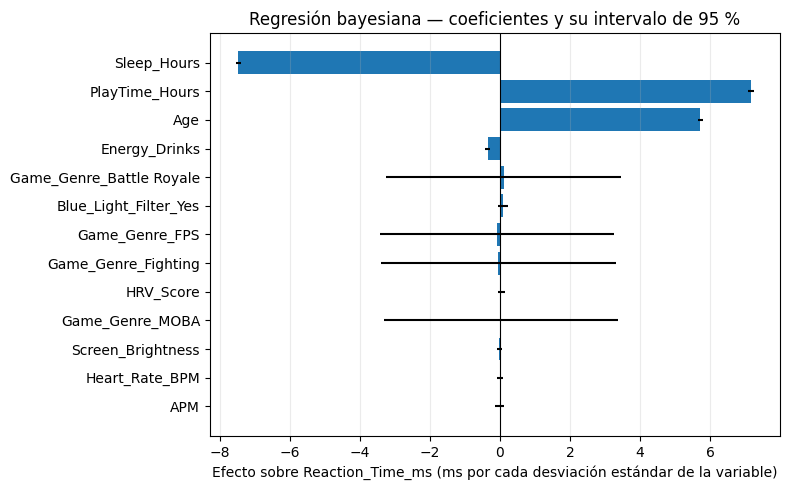

In [4]:
bayes_model = Pipeline([('preprocessor', make_scaled_preprocessor()), ('model', BayesianRidge())])

X_cv_common, y_cv_common = tuning_sample(X_train, y_train, COMMON_CV_SAMPLE, random_state=2026)
s = cross_validate(bayes_model, X_cv_common, y_cv_common, cv=cv5, scoring=scoring, n_jobs=-1)
print(f"Regresión bayesiana — RMSE CV: {-s['test_RMSE'].mean():.4f} ± {s['test_RMSE'].std():.4f} | R² CV: {s['test_R2'].mean():.4f}")

bayes_model, pred_bayes, row_bayes = fit_and_test('Regresión bayesiana', bayes_model, X_train, y_train, X_test, y_test)
row_bayes['Entrega'] = 'Entrega 2'
final_rows.append(row_bayes); test_predictions['Regresión bayesiana'] = pred_bayes
display(pd.DataFrame([row_bayes]).round(4))

br = bayes_model.named_steps['model']
names = bayes_model.named_steps['preprocessor'].get_feature_names_out()
coef_std = np.sqrt(np.diag(br.sigma_))
coefs = pd.DataFrame({'Variable': names, 'Coeficiente_ms_por_desv_std': br.coef_, 'Incertidumbre_(±1_std)': coef_std})
coefs = coefs.reindex(coefs['Coeficiente_ms_por_desv_std'].abs().sort_values(ascending=False).index)
print(f"Precisión del ruido α = {br.alpha_:.5f}  -> desviación del ruido ≈ {1/np.sqrt(br.alpha_):.2f} ms")
print(f"Precisión de los coeficientes λ = {br.lambda_:.5f}")
display(coefs.round(3))
coefs.to_csv(RESULTS_DIR / 'e2_tabla_01_bayes_coeficientes.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 5))
c = coefs.iloc[::-1]
ax.barh(c['Variable'], c['Coeficiente_ms_por_desv_std'], xerr=1.96 * c['Incertidumbre_(±1_std)'], color='tab:blue')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Efecto sobre Reaction_Time_ms (ms por cada desviación estándar de la variable)')
ax.set_title('Regresión bayesiana — coeficientes y su intervalo de 95 %')
ax.grid(axis='x', alpha=.25)
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'e2_fig_01_bayes_coeficientes.png', dpi=150, bbox_inches='tight'); plt.show()

**Predicción con incertidumbre.** A diferencia de los demás modelos, la regresión bayesiana dice cuánto confía en cada predicción. Abajo hay 8 jugadores de TEST: su tiempo real, lo que predijo el modelo y el intervalo del 95 % (predicción ± 1.96·desviación).

In [5]:
Xte_bayes = bayes_model.named_steps['preprocessor'].transform(X_test)
mean_pred, std_pred = br.predict(Xte_bayes, return_std=True)
sample_idx = np.random.default_rng(RANDOM_STATE).choice(len(X_test), size=8, replace=False)
ejemplos = pd.DataFrame({
    'Real_ms': y_test.iloc[sample_idx].to_numpy(),
    'Predicho_ms': mean_pred[sample_idx],
    'Incertidumbre_±1.96std': 1.96 * std_pred[sample_idx],
})
ejemplos['Error_ms'] = ejemplos['Real_ms'] - ejemplos['Predicho_ms']
ejemplos['Real_dentro_del_intervalo'] = ejemplos['Error_ms'].abs() <= ejemplos['Incertidumbre_±1.96std']
display(ejemplos.round(2))
cobertura = (np.abs(y_test.to_numpy() - mean_pred) <= 1.96 * std_pred).mean()
print(f"En TODO el TEST, el valor real cae dentro del intervalo del 95 % en el {cobertura:.1%} de los jugadores.")

,Real_ms,Predicho_ms,Incertidumbre_±1.96std,Error_ms,Real_dentro_del_intervalo
0,230.83,256.39,29.72,-25.56,True
1,283.01,265.84,29.72,17.17,True
2,251.81,270.49,29.72,-18.68,True
3,253.91,275.42,29.72,-21.51,True
4,258.00,273.91,29.72,-15.91,True
5,284.60,274.34,29.72,10.26,True
6,277.94,270.35,29.72,7.59,True
7,226.66,266.19,29.72,-39.53,False


En TODO el TEST, el valor real cae dentro del intervalo del 95 % en el 95.1% de los jugadores.


## 5. Modelo nuevo 2 — Máquina de Soporte Vectorial para regresión (SVR)

**Cómo funciona.** La SVR busca una función que se equivoque **menos de ε** en la mayor cantidad de puntos posible (un "tubo" de ancho ε alrededor de la predicción). Los puntos dentro del tubo no cuentan como error. Los que quedan fuera se penalizan con un peso **C**, y son los **vectores de soporte**: los únicos que definen el modelo. El **kernel** decide la forma de la función:

- `linear`: una relación lineal (un hiperplano).
- `rbf` (radial): curvas no lineales, por medio de una medida de similitud entre puntos.

**Selección por CV.** Rejilla de kernel × C × ε con 5 folds sobre una muestra de 8,000 filas de TRAIN.

**Costo computacional:** una SVM con kernel crece aproximadamente con el **cuadrado** del número de filas. Con 175,000 filas no es viable entrenar una SVR RBF en un tiempo razonable. Por eso, si gana el kernel RBF, el modelo final se entrena con una muestra de 30,000 filas. Si gana el lineal, se usa `LinearSVR`, la misma formulación optimizada para muchos datos, con el TRAIN completo.

Tiempo de la búsqueda: 177.9 s
Mejores parámetros SVR: {'model__C': 1, 'model__epsilon': 5, 'model__kernel': 'linear'} | RMSE CV: 15.1201


,Kernel,C,epsilon,RMSE_CV,RMSE_CV_std,R2_CV,Tiempo_fit_s
4,linear,1,5.0,15.1201,0.2363,0.3752,1.1633
10,linear,10,5.0,15.1203,0.2362,0.3752,2.1176
16,linear,100,5.0,15.1203,0.2361,0.3752,8.9022
0,linear,1,0.5,15.1214,0.2401,0.3751,1.5149
12,linear,100,0.5,15.1220,0.2399,0.3750,11.1124
6,linear,10,0.5,15.1222,0.2401,0.3750,2.6612
2,linear,1,2.0,15.1239,0.2411,0.3749,1.3965
8,linear,10,2.0,15.1252,0.2412,0.3748,2.4766
14,linear,100,2.0,15.1253,0.2413,0.3748,10.4511
11,rbf,10,5.0,15.3369,0.2215,0.3572,1.5522


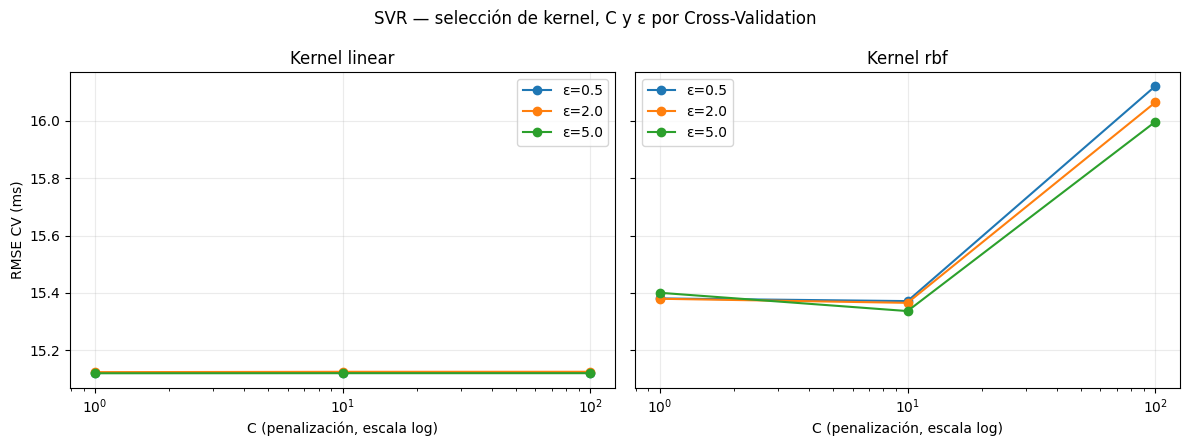

In [6]:
X_svr_cv, y_svr_cv = tuning_sample(X_train, y_train, SVR_TUNING_SAMPLE)
svr_grid = GridSearchCV(
    Pipeline([('preprocessor', make_scaled_preprocessor()), ('model', SVR())]),
    param_grid={'model__kernel': ['linear', 'rbf'],
                'model__C': [1, 10, 100],
                'model__epsilon': [0.5, 2, 5]},
    scoring=scoring, refit='RMSE', cv=cv5, n_jobs=-1)
t0 = time.time(); svr_grid.fit(X_svr_cv, y_svr_cv)
print(f'Tiempo de la búsqueda: {time.time()-t0:.1f} s')
print('Mejores parámetros SVR:', svr_grid.best_params_, '| RMSE CV:', round(-svr_grid.best_score_, 4))

svr_cv = pd.DataFrame(svr_grid.cv_results_)
svr_cv['RMSE_CV'] = -svr_cv['mean_test_RMSE']
svr_cv['R2_CV'] = svr_cv['mean_test_R2']
svr_tab = svr_cv[['param_model__kernel', 'param_model__C', 'param_model__epsilon', 'RMSE_CV', 'std_test_RMSE', 'R2_CV', 'mean_fit_time']].sort_values('RMSE_CV')
svr_tab.columns = ['Kernel', 'C', 'epsilon', 'RMSE_CV', 'RMSE_CV_std', 'R2_CV', 'Tiempo_fit_s']
display(svr_tab.round(4))
svr_tab.to_csv(RESULTS_DIR / 'e2_tabla_02_svr_cv.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, kernel in zip(axes, ['linear', 'rbf']):
    sub = svr_tab[svr_tab['Kernel'] == kernel]
    for eps, g in sub.groupby('epsilon'):
        g = g.sort_values('C')
        ax.plot(g['C'], g['RMSE_CV'], marker='o', label=f'ε={eps}')
    ax.set_xscale('log'); ax.set_xlabel('C (penalización, escala log)'); ax.set_title(f'Kernel {kernel}')
    ax.grid(alpha=.25); ax.legend()
axes[0].set_ylabel('RMSE CV (ms)')
fig.suptitle('SVR — selección de kernel, C y ε por Cross-Validation')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'e2_fig_02_svr_cv.png', dpi=150, bbox_inches='tight'); plt.show()

In [7]:
best = svr_grid.best_params_
if best['model__kernel'] == 'linear':
    svr_final = Pipeline([('preprocessor', make_scaled_preprocessor()),
                          ('model', LinearSVR(C=best['model__C'], epsilon=best['model__epsilon'],
                                              dual='auto', max_iter=20000, random_state=RANDOM_STATE))])
    X_svr_fit, y_svr_fit = X_train, y_train
    svr_name = f"SVR lineal (C={best['model__C']}, ε={best['model__epsilon']})"
else:
    svr_final = Pipeline([('preprocessor', make_scaled_preprocessor()),
                          ('model', SVR(kernel='rbf', C=best['model__C'], epsilon=best['model__epsilon']))])
    X_svr_fit, y_svr_fit = tuning_sample(X_train, y_train, SVR_FINAL_SAMPLE)
    svr_name = f"SVR RBF (C={best['model__C']}, ε={best['model__epsilon']})"

print(f'Entrenando {svr_name} con {len(X_svr_fit):,} filas de TRAIN...')
svr_final, pred_svr, row_svr = fit_and_test(svr_name, svr_final, X_svr_fit, y_svr_fit, X_test, y_test)
row_svr['Entrega'] = 'Entrega 2'
final_rows.append(row_svr); test_predictions[svr_name] = pred_svr
display(pd.DataFrame([row_svr]).round(4))

# Comparación del kernel ganador vs. el otro, ambos con su mejor (C, ε) y la MISMA muestra de CV
kernel_comp = svr_tab.loc[svr_tab.groupby('Kernel')['RMSE_CV'].idxmin()].reset_index(drop=True)
print('Mejor configuración de cada kernel (CV):')
display(kernel_comp.round(4))

Entrenando SVR lineal (C=1, ε=5) con 175,000 filas de TRAIN...


,Modelo,fit_s,predict_s,MAE,MSE,RMSE,R2,Entrega
0,"SVR lineal (C=1, ε=5)",1.2809,0.0665,12.0135,226.8563,15.0617,0.3729,Entrega 2


Mejor configuración de cada kernel (CV):


,Kernel,C,epsilon,RMSE_CV,RMSE_CV_std,R2_CV,Tiempo_fit_s
0,linear,1,5.0,15.1201,0.2363,0.3752,1.1633
1,rbf,10,5.0,15.3369,0.2215,0.3572,1.5522


## 6. Modelo nuevo 3 — Red Neuronal Artificial (Perceptrón multicapa, `MLPRegressor`)

**Cómo funciona.** Cada neurona recibe las variables de entrada, las multiplica por unos **pesos** (las **conexiones**), suma un sesgo y aplica una **función de activación** (ReLU: deja pasar los valores positivos y anula los negativos). Las neuronas se organizan en **capas ocultas**: cada capa recibe la salida de la anterior, lo que permite aprender relaciones no lineales y combinaciones de variables. La red ajusta sus pesos para reducir el error, mediante descenso de gradiente (optimizador Adam) y retropropagación.

### 6.1 Las 3 redes de la entrega: una suave y dos que incrementan neuronas y capas ocultas

| Red | Capas ocultas | Neuronas por capa | Arquitectura |
|---|---|---|---|
| **Suave** | 1 | 16 | (16) |
| **Intermedia** | 2 | 64 | (64, 64) |
| **Grande** | 3 | 128 | (128, 128, 128) |

De una red a la siguiente aumentan **a la vez** las capas ocultas y las neuronas, así que el número de **conexiones** (pesos entre neuronas) crece muy rápido. La pregunta es: **¿el modelo mejora al hacerlo más grande?**

Cada red se evalúa de dos formas: con validación cruzada de 5 folds sobre 20,000 filas de TRAIN (para tener su error promedio y su variabilidad) y entrenada con el TRAIN completo y evaluada **una vez** sobre TEST.

**Detalles de entrenamiento (iguales para las 3):** activación ReLU, optimizador Adam, **early stopping** (se aparta el 10 % de los datos de entrenamiento y la red se detiene cuando ese error deja de mejorar, para evitar el sobreajuste) y la **variable objetivo escalada** (`TransformedTargetRegressor`), porque la red aprende mejor prediciendo valores cercanos a 0 que valores alrededor de 260 ms.

In [8]:
THREE_NETS = {
    'Red neuronal suave (16)': (16,),
    'Red neuronal intermedia (64, 64)': (64, 64),
    'Red neuronal grande (128, 128, 128)': (128, 128, 128),
}


def make_mlp(hidden):
    return Pipeline([('preprocessor', make_scaled_preprocessor()),
                     ('model', TransformedTargetRegressor(
                         regressor=MLPRegressor(hidden_layer_sizes=hidden, activation='relu', solver='adam',
                                                early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                                                max_iter=300, random_state=RANDOM_STATE),
                         transformer=StandardScaler()))])


n_inputs = make_scaled_preprocessor().fit(X_train.head(1000)).transform(X_train.head(1)).shape[1]


def n_connections(hidden, n_in=n_inputs, n_out=1):
    sizes = [n_in] + list(hidden) + [n_out]
    return sum(a * b for a, b in zip(sizes[:-1], sizes[1:]))


def veredicto(rmse_nuevo, rmse_antes, tolerancia):
    d = rmse_nuevo - rmse_antes
    if abs(d) <= tolerancia:
        return f'Quedó igual ({d:+.3f})'
    return f'Mejoró ({d:+.3f})' if d < 0 else f'Empeoró ({d:+.3f})'


X_mlp_cv, y_mlp_cv = tuning_sample(X_train, y_train, MLP_GRID_SAMPLE)
net_rows, trained_nets = [], {}
for name, hidden in THREE_NETS.items():
    s = cross_validate(make_mlp(hidden), X_mlp_cv, y_mlp_cv, cv=cv5, scoring=scoring, n_jobs=-1)
    model, pred, row = fit_and_test(name, make_mlp(hidden), X_train, y_train, X_test, y_test)
    row['Entrega'] = 'Entrega 2'
    final_rows.append(dict(row)); test_predictions[name] = pred; trained_nets[name] = model
    net_rows.append({'Red': name, 'Capas_ocultas': len(hidden), 'Neuronas_por_capa': hidden[0],
                     'Conexiones': n_connections(hidden),
                     'RMSE_CV': -s['test_RMSE'].mean(), 'RMSE_CV_std': s['test_RMSE'].std(),
                     'RMSE_TEST': row['RMSE'], 'R2_TEST': row['R2'], 'MAE_TEST': row['MAE'],
                     'Epocas': model.named_steps['model'].regressor_.n_iter_, 'Tiempo_entrenamiento_s': row['fit_s']})
    print(f"{name:38s} conexiones={net_rows[-1]['Conexiones']:>6,}  RMSE CV={net_rows[-1]['RMSE_CV']:.3f}  "
          f"RMSE TEST={row['RMSE']:.3f}  ({row['fit_s']:.1f} s)")

tres_redes = pd.DataFrame(net_rows)
tol = tres_redes['RMSE_CV_std'].mean()
tres_redes['Respecto_a_la_red_anterior'] = ['— (punto de partida)'] + [
    veredicto(tres_redes.loc[i, 'RMSE_CV'], tres_redes.loc[i - 1, 'RMSE_CV'], tol) for i in range(1, len(tres_redes))]
print(f'\nCriterio: una diferencia de RMSE CV menor que ±{tol:.3f} ms (desviación estándar media del CV) es "quedó igual".')
display(tres_redes.round(4))
tres_redes.to_csv(RESULTS_DIR / 'e2_tabla_03_tres_redes_neuronales.csv', index=False)

Red neuronal suave (16)                conexiones=   224  RMSE CV=15.131  RMSE TEST=14.996  (7.0 s)


Red neuronal intermedia (64, 64)       conexiones= 4,992  RMSE CV=15.132  RMSE TEST=14.998  (17.3 s)


Red neuronal grande (128, 128, 128)    conexiones=34,560  RMSE CV=15.133  RMSE TEST=14.996  (40.3 s)

Criterio: una diferencia de RMSE CV menor que ±0.091 ms (desviación estándar media del CV) es "quedó igual".


,Red,Capas_ocultas,Neuronas_por_capa,Conexiones,RMSE_CV,RMSE_CV_std,RMSE_TEST,R2_TEST,MAE_TEST,Epocas,Tiempo_entrenamiento_s,Respecto_a_la_red_anterior
0,Red neuronal suave (16),1,16,224,15.1312,0.0904,14.9960,0.3784,11.9592,23,6.9967,— (punto de partida)
1,"Red neuronal intermedia (64, 64)",2,64,4992,15.1320,0.0823,14.9983,0.3782,11.9553,20,17.2571,Quedó igual (+0.001)
2,"Red neuronal grande (128, 128, 128)",3,128,34560,15.1331,0.0994,14.9956,0.3784,11.9533,16,40.3338,Quedó igual (+0.001)


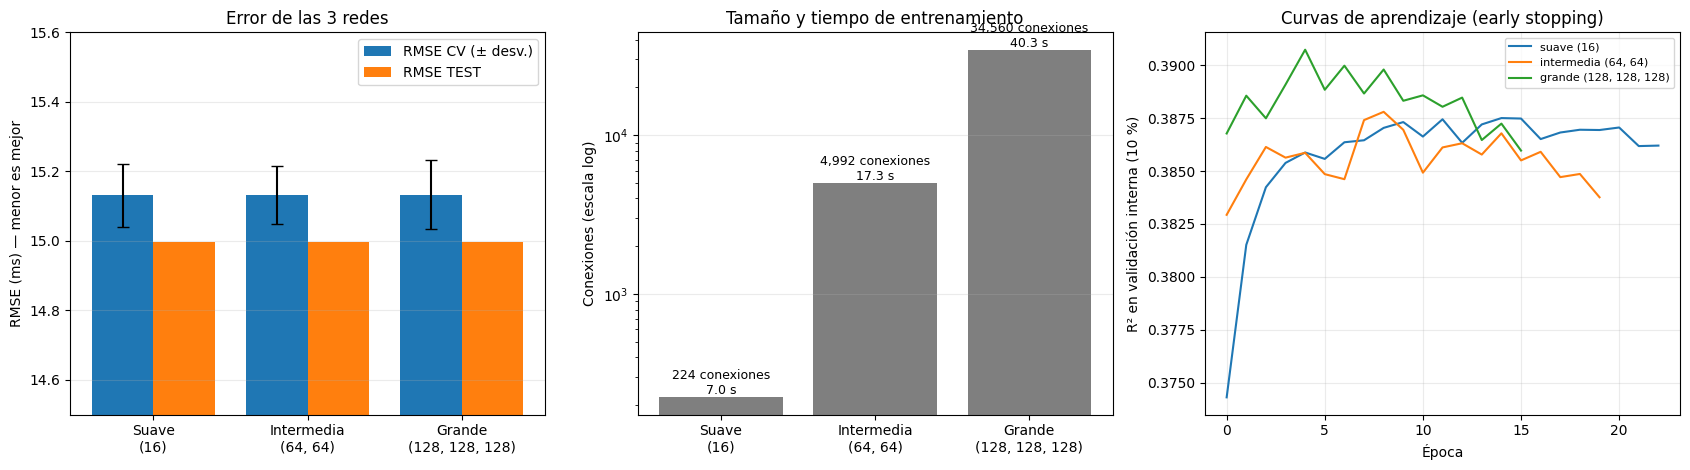

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
labels = ['Suave\n(16)', 'Intermedia\n(64, 64)', 'Grande\n(128, 128, 128)']
x = np.arange(len(tres_redes))
axes[0].bar(x - 0.2, tres_redes['RMSE_CV'], 0.4, yerr=tres_redes['RMSE_CV_std'], capsize=4, label='RMSE CV (± desv.)')
axes[0].bar(x + 0.2, tres_redes['RMSE_TEST'], 0.4, label='RMSE TEST')
axes[0].set_ylim(14.5, 15.6); axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_ylabel('RMSE (ms) — menor es mejor'); axes[0].set_title('Error de las 3 redes'); axes[0].legend(); axes[0].grid(axis='y', alpha=.25)
axes[1].bar(x, tres_redes['Conexiones'], color='tab:gray')
for xi, (c, t) in enumerate(zip(tres_redes['Conexiones'], tres_redes['Tiempo_entrenamiento_s'])):
    axes[1].text(xi, c, f'{c:,} conexiones\n{t:.1f} s', ha='center', va='bottom', fontsize=9)
axes[1].set_yscale('log'); axes[1].set_xticks(x); axes[1].set_xticklabels(labels)
axes[1].set_ylabel('Conexiones (escala log)'); axes[1].set_title('Tamaño y tiempo de entrenamiento'); axes[1].grid(axis='y', alpha=.25)
for name, model in trained_nets.items():
    axes[2].plot(model.named_steps['model'].regressor_.validation_scores_, label=name.replace('Red neuronal ', ''))
axes[2].set_xlabel('Época'); axes[2].set_ylabel('R² en validación interna (10 %)')
axes[2].set_title('Curvas de aprendizaje (early stopping)'); axes[2].grid(alpha=.25); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'e2_fig_03_tres_redes_neuronales.png', dpi=150, bbox_inches='tight'); plt.show()

### 6.2 Análisis complementario: separar el efecto de las capas y el de las neuronas

En las 3 redes de arriba cambian capas y neuronas al mismo tiempo, así que no se sabe cuál de los dos factores explica el resultado. Para separarlos, se prueban **todas las combinaciones** de 1, 2 y 3 capas con 16, 64 y 128 neuronas (9 redes, entre ellas las 3 anteriores), con la misma validación cruzada. Se compara cada red con la que tiene **una capa menos** (mismas neuronas) y con la que tiene **menos neuronas** (mismas capas).

,Arquitectura,Conexiones,RMSE_CV,RMSE_CV_std,R2_CV,Tiempo_fit_medio_s,Al_agregar_una_capa,Al_aumentar_neuronas
0,"(16,)",224,15.1312,0.0904,0.3722,1.3874,—,—
1,"(64,)",896,15.1268,0.0867,0.3726,1.1695,—,Quedó igual (-0.004)
2,"(128,)",1792,15.1268,0.0473,0.3725,1.3040,—,Quedó igual (-0.000)
3,"(16, 16)",480,15.1758,0.1088,0.3685,1.3172,Quedó igual (+0.045),—
4,"(64, 64)",4992,15.1320,0.0823,0.3721,1.5005,Quedó igual (+0.005),Quedó igual (-0.044)
5,"(128, 128)",18176,15.1521,0.0873,0.3705,2.4693,Quedó igual (+0.025),Quedó igual (+0.020)
6,"(16, 16, 16)",736,15.1605,0.0752,0.3698,1.9428,Quedó igual (-0.015),—
7,"(64, 64, 64)",9088,15.1593,0.0881,0.3699,1.6329,Quedó igual (+0.027),Quedó igual (-0.001)
8,"(128, 128, 128)",34560,15.1331,0.0994,0.3720,3.5650,Quedó igual (-0.019),Quedó igual (-0.026)


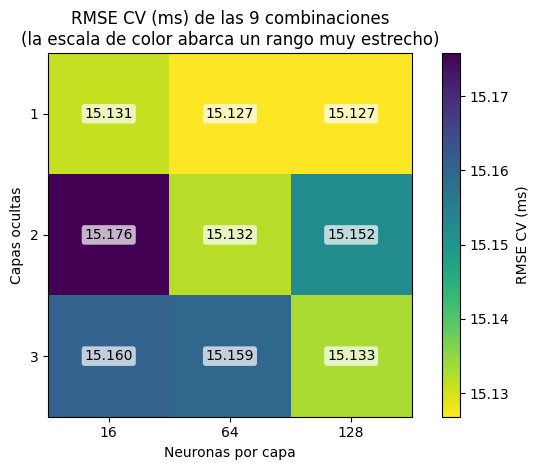

In [10]:
LAYERS, NEURONS = [1, 2, 3], [16, 64, 128]
mlp_rows = []
for n_layers in LAYERS:
    for n_neurons in NEURONS:
        hidden = tuple([n_neurons] * n_layers)
        s = cross_validate(make_mlp(hidden), X_mlp_cv, y_mlp_cv, cv=cv5, scoring=scoring, n_jobs=-1)
        mlp_rows.append({'Capas': n_layers, 'Neuronas_por_capa': n_neurons, 'Arquitectura': str(hidden),
                         'Conexiones': n_connections(hidden),
                         'RMSE_CV': -s['test_RMSE'].mean(), 'RMSE_CV_std': s['test_RMSE'].std(),
                         'R2_CV': s['test_R2'].mean(), 'Tiempo_fit_medio_s': s['fit_time'].mean()})
mlp_grid = pd.DataFrame(mlp_rows)
g = mlp_grid.set_index(['Capas', 'Neuronas_por_capa'])
tol_grid = mlp_grid['RMSE_CV_std'].mean()
vs_capas, vs_neuronas = [], []
for (cap, neu), r in g.iterrows():
    vs_capas.append('—' if cap == 1 else veredicto(r['RMSE_CV'], g.loc[(cap - 1, neu), 'RMSE_CV'], tol_grid))
    k = NEURONS.index(neu)
    vs_neuronas.append('—' if k == 0 else veredicto(r['RMSE_CV'], g.loc[(cap, NEURONS[k - 1]), 'RMSE_CV'], tol_grid))
mlp_grid['Al_agregar_una_capa'] = vs_capas
mlp_grid['Al_aumentar_neuronas'] = vs_neuronas
display(mlp_grid[['Arquitectura', 'Conexiones', 'RMSE_CV', 'RMSE_CV_std', 'R2_CV', 'Tiempo_fit_medio_s',
                  'Al_agregar_una_capa', 'Al_aumentar_neuronas']].round(4))
mlp_grid.to_csv(RESULTS_DIR / 'e2_tabla_03b_red_neuronal_rejilla.csv', index=False)

fig, ax = plt.subplots(figsize=(6.5, 4.8))
heat = mlp_grid.pivot(index='Capas', columns='Neuronas_por_capa', values='RMSE_CV')
im = ax.imshow(heat.values, cmap='viridis_r')
ax.set_xticks(range(len(NEURONS))); ax.set_xticklabels(NEURONS)
ax.set_yticks(range(len(LAYERS))); ax.set_yticklabels(LAYERS)
ax.set_xlabel('Neuronas por capa'); ax.set_ylabel('Capas ocultas')
for i in range(len(LAYERS)):
    for j in range(len(NEURONS)):
        ax.text(j, i, f'{heat.values[i, j]:.3f}', ha='center', va='center', color='black', fontsize=10,
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='none'))
ax.set_title('RMSE CV (ms) de las 9 combinaciones\n(la escala de color abarca un rango muy estrecho)')
plt.colorbar(im, ax=ax, label='RMSE CV (ms)')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'e2_fig_04_red_neuronal_rejilla.png', dpi=150, bbox_inches='tight'); plt.show()

## 7. Comparación de todos los modelos (Entrega 1 + Entrega 2)

### 7.1 Sobre el mismo TEST (evaluación final, una sola vez)

,Ranking,Modelo,Entrega,MAE,RMSE,R2,Mejora_RMSE_vs_baseline_%,fit_s,predict_s
0,1,"Red neuronal grande (128, 128, 128)",Entrega 2,11.9533,14.9956,0.3784,21.1620,40.3338,0.3312
1,2,Red neuronal suave (16),Entrega 2,11.9592,14.9960,0.3784,21.1596,6.9967,0.0781
2,3,"Red neuronal intermedia (64, 64)",Entrega 2,11.9553,14.9983,0.3782,21.1477,17.2571,0.1367
3,4,Regresión bayesiana,Entrega 2,12.0130,15.0609,0.3730,20.8186,0.4401,0.1090
4,5,"SVR lineal (C=1, ε=5)",Entrega 2,12.0135,15.0617,0.3729,20.8141,1.2809,0.0665
5,6,Random Forest podado CV,Entrega 1,12.0862,15.1495,0.3656,20.3526,13.1175,0.2064
6,7,KNN K=50 (distance),Entrega 1,12.1874,15.2923,0.3536,19.6019,0.7907,76.4685
7,8,Árbol podado CV,Entrega 1,12.2279,15.3323,0.3502,19.3918,0.9908,0.0799
8,9,Baseline (media),Referencia,15.1553,19.0207,-0.0000,0.0000,0.2819,0.0599


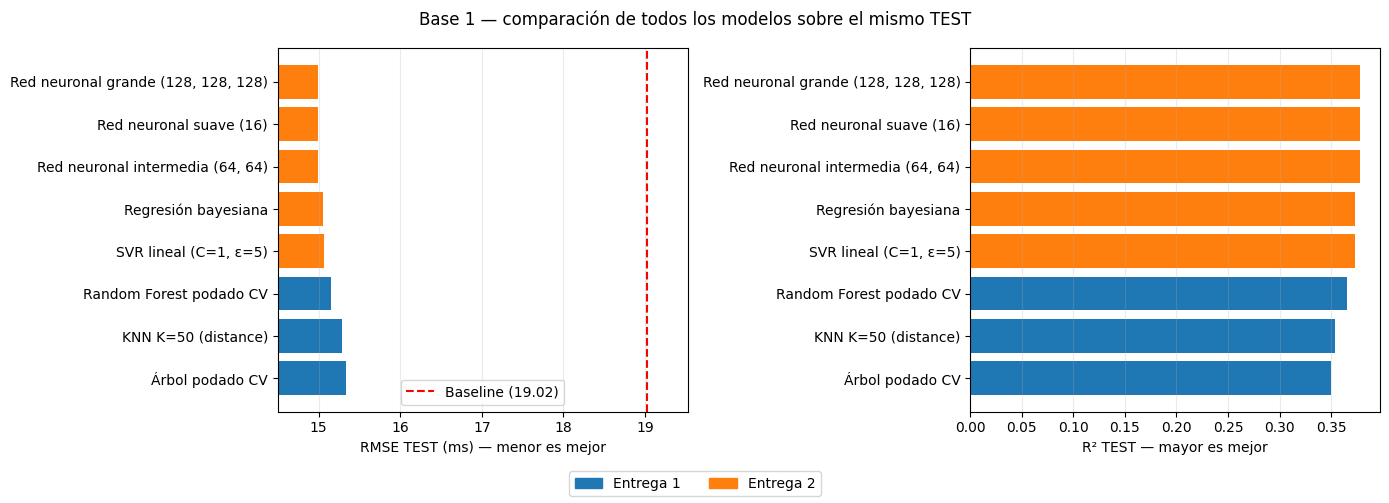

In [11]:
final_df = pd.DataFrame(final_rows)
base_rmse = final_df.loc[final_df['Modelo'] == 'Baseline (media)', 'RMSE'].iloc[0]
final_df['Mejora_RMSE_vs_baseline_%'] = (base_rmse - final_df['RMSE']) / base_rmse * 100
final_df = final_df.sort_values('RMSE').reset_index(drop=True)
final_df.insert(0, 'Ranking', range(1, len(final_df) + 1))
display(final_df[['Ranking', 'Modelo', 'Entrega', 'MAE', 'RMSE', 'R2', 'Mejora_RMSE_vs_baseline_%', 'fit_s', 'predict_s']].round(4))
final_df.to_csv(RESULTS_DIR / 'e2_tabla_04_comparacion_final_test.csv', index=False)

plot_df = final_df[final_df['Modelo'] != 'Baseline (media)'].sort_values('RMSE', ascending=False)
colors = ['tab:orange' if e == 'Entrega 2' else 'tab:blue' for e in plot_df['Entrega']]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(plot_df['Modelo'], plot_df['RMSE'], color=colors)
axes[0].axvline(base_rmse, color='red', linestyle='--', label=f'Baseline ({base_rmse:.2f})')
axes[0].set_xlim(14.5, base_rmse + 0.5); axes[0].set_xlabel('RMSE TEST (ms) — menor es mejor'); axes[0].legend()
axes[1].barh(plot_df['Modelo'], plot_df['R2'], color=colors)
axes[1].set_xlabel('R² TEST — mayor es mejor')
for ax in axes: ax.grid(axis='x', alpha=.25)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color='tab:blue', label='Entrega 1'), Patch(color='tab:orange', label='Entrega 2')],
           loc='lower center', ncol=2)
fig.suptitle('Base 1 — comparación de todos los modelos sobre el mismo TEST')
plt.tight_layout(rect=[0, 0.06, 1, 1]); plt.savefig(RESULTS_DIR / 'e2_fig_05_comparacion_final.png', dpi=150, bbox_inches='tight'); plt.show()

### 7.2 Sobre los mismos folds de validación cruzada

La misma muestra de 8,000 filas y los mismos 5 folds de la "comparación común" de la Entrega 1. Así se ve si el orden de los modelos se mantiene también fuera del TEST.

In [12]:
common_models = dict(entrega1_models)
common_models['Regresión bayesiana'] = Pipeline([('preprocessor', make_scaled_preprocessor()), ('model', BayesianRidge())])
if best['model__kernel'] == 'linear':
    common_models[svr_name] = Pipeline([('preprocessor', make_scaled_preprocessor()),
                                        ('model', LinearSVR(C=best['model__C'], epsilon=best['model__epsilon'],
                                                            dual='auto', max_iter=20000, random_state=RANDOM_STATE))])
else:
    common_models[svr_name] = Pipeline([('preprocessor', make_scaled_preprocessor()),
                                        ('model', SVR(kernel='rbf', C=best['model__C'], epsilon=best['model__epsilon']))])
for name, hidden in THREE_NETS.items():
    common_models[name] = make_mlp(hidden)

cv_rows = []
for name, model in common_models.items():
    s = cross_validate(model, X_cv_common, y_cv_common, cv=cv5, scoring=scoring, n_jobs=-1)
    cv_rows.append({'Modelo': name, 'RMSE_CV': -s['test_RMSE'].mean(), 'RMSE_CV_std': s['test_RMSE'].std(),
                    'MAE_CV': -s['test_MAE'].mean(), 'R2_CV': s['test_R2'].mean()})
common_cv = pd.DataFrame(cv_rows).sort_values('RMSE_CV').reset_index(drop=True)
display(common_cv.round(4))
common_cv.to_csv(RESULTS_DIR / 'e2_tabla_05_comparacion_cv_comun.csv', index=False)

orden_test = final_df[final_df['Modelo'] != 'Baseline (media)']['Modelo'].tolist()
orden_cv = common_cv[common_cv['Modelo'] != 'Baseline (media)']['Modelo'].tolist()
print('Orden en TEST:', orden_test)
print('Orden en CV  :', orden_cv)

,Modelo,RMSE_CV,RMSE_CV_std,MAE_CV,R2_CV
0,Regresión bayesiana,15.0483,0.3281,12.0093,0.3886
1,"SVR lineal (C=1, ε=5)",15.0768,0.3288,12.0268,0.3863
2,"Red neuronal intermedia (64, 64)",15.1062,0.3681,12.0312,0.3838
3,Red neuronal suave (16),15.1326,0.3340,12.0581,0.3817
4,"Red neuronal grande (128, 128, 128)",15.1401,0.3453,12.0612,0.3811
5,Random Forest podado CV,15.3361,0.3344,12.2590,0.3650
6,KNN K=50 (distance),15.6981,0.2967,12.4916,0.3346
7,Árbol podado CV,15.8501,0.3087,12.6504,0.3216
8,Baseline (media),19.2487,0.3250,15.3944,-0.0005


Orden en TEST: ['Red neuronal grande (128, 128, 128)', 'Red neuronal suave (16)', 'Red neuronal intermedia (64, 64)', 'Regresión bayesiana', 'SVR lineal (C=1, ε=5)', 'Random Forest podado CV', 'KNN K=50 (distance)', 'Árbol podado CV']
Orden en CV  : ['Regresión bayesiana', 'SVR lineal (C=1, ε=5)', 'Red neuronal intermedia (64, 64)', 'Red neuronal suave (16)', 'Red neuronal grande (128, 128, 128)', 'Random Forest podado CV', 'KNN K=50 (distance)', 'Árbol podado CV']


### 7.3 Datos reales frente a predicciones

Cada punto es un jugador de TEST. Si el modelo fuera perfecto, todos los puntos caerían sobre la diagonal roja. Se muestra una muestra de 4,000 jugadores para que la figura sea legible.

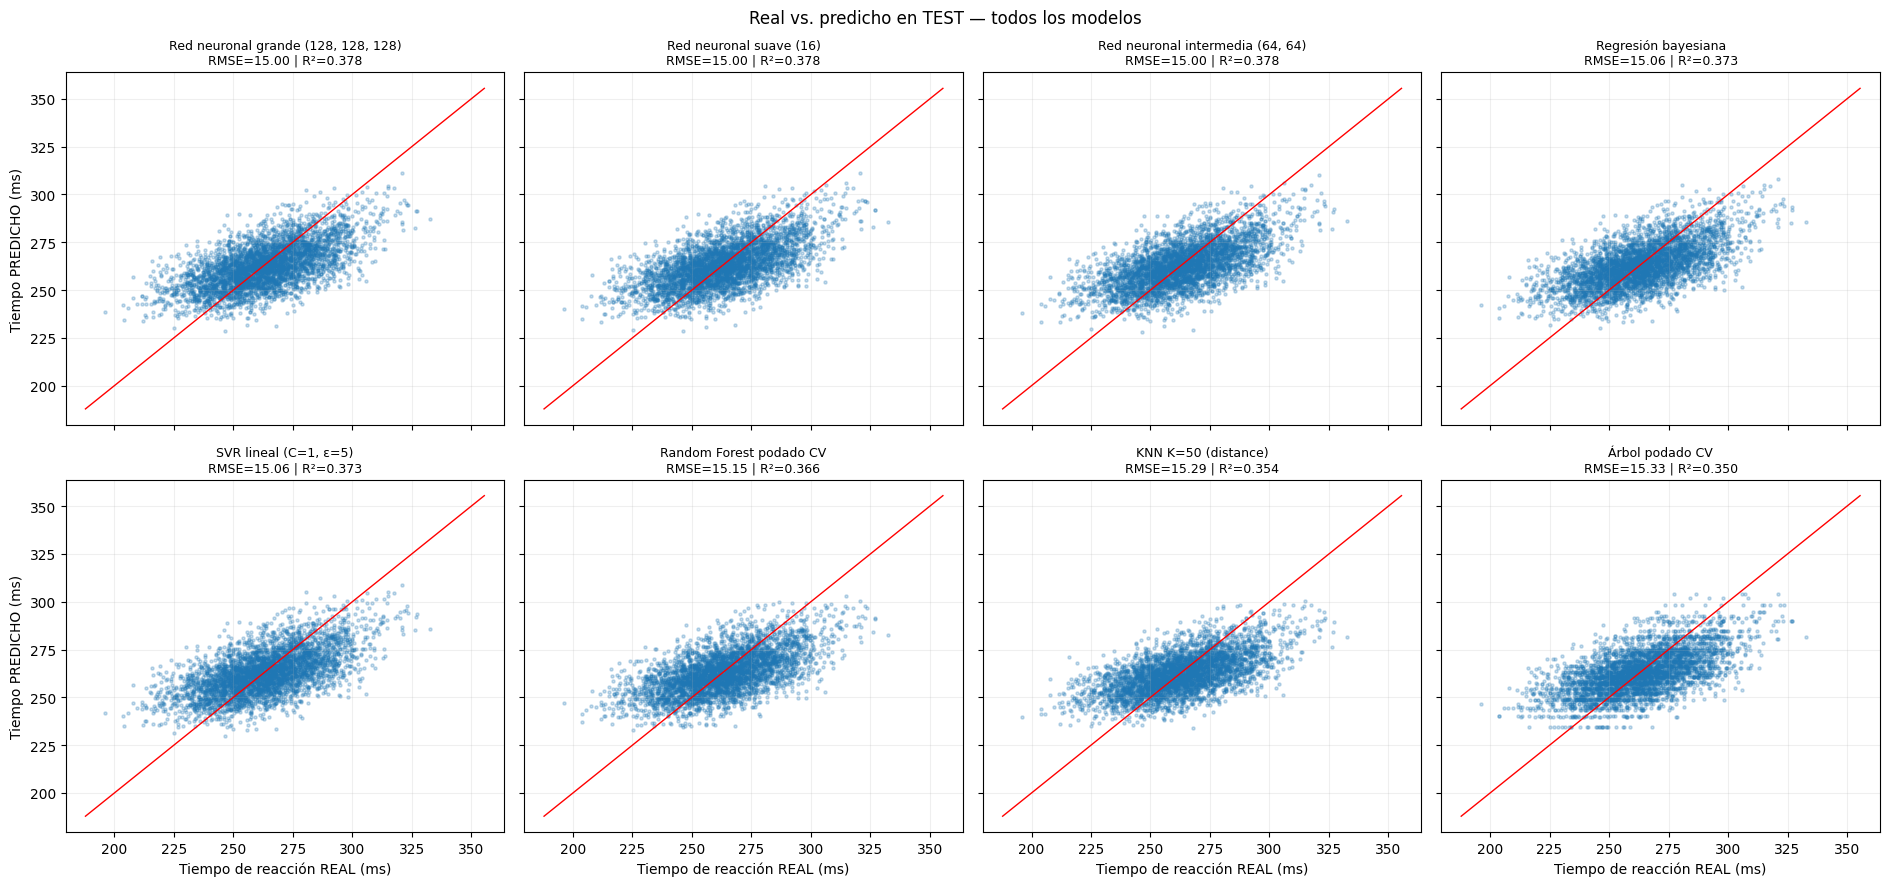

Rango de los valores REALES en TEST: 187.9 a 355.5 ms


,Modelo,Rango_predicho_min,Rango_predicho_max
0,"Red neuronal grande (128, 128, 128)",222.5,321.6
1,Red neuronal suave (16),224.0,321.0
2,"Red neuronal intermedia (64, 64)",225.0,322.7
3,Regresión bayesiana,224.7,323.7
4,"SVR lineal (C=1, ε=5)",224.3,323.9
5,Random Forest podado CV,232.6,306.9
6,KNN K=50 (distance),229.2,307.5
7,Árbol podado CV,234.7,304.0


In [13]:
models_to_plot = [m for m in final_df['Modelo'] if m != 'Baseline (media)']
vis_idx = np.random.default_rng(RANDOM_STATE).choice(len(y_test), size=4000, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(19, 9), sharex=True, sharey=True)
lims = [y_test.min(), y_test.max()]
for ax, name in zip(axes.ravel(), models_to_plot):
    pred = test_predictions[name]
    ax.scatter(y_test.iloc[vis_idx], pred[vis_idx], s=5, alpha=.25)
    ax.plot(lims, lims, color='red', linewidth=1)
    r = final_df.set_index('Modelo').loc[name]
    ax.set_title(f"{name}\nRMSE={r['RMSE']:.2f} | R²={r['R2']:.3f}", fontsize=9)
    ax.grid(alpha=.2)
for ax in axes[-1]: ax.set_xlabel('Tiempo de reacción REAL (ms)')
for ax in axes[:, 0]: ax.set_ylabel('Tiempo PREDICHO (ms)')
fig.suptitle('Real vs. predicho en TEST — todos los modelos')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'e2_fig_06_real_vs_predicho.png', dpi=140, bbox_inches='tight'); plt.show()

resumen_pred = pd.DataFrame({'Modelo': models_to_plot,
                             'Rango_predicho_min': [test_predictions[m].min() for m in models_to_plot],
                             'Rango_predicho_max': [test_predictions[m].max() for m in models_to_plot]})
print(f'Rango de los valores REALES en TEST: {y_test.min():.1f} a {y_test.max():.1f} ms')
display(resumen_pred.round(1))

## 8. Conclusiones de la Entrega 2 (Base 1)

| Puesto (TEST) | Modelo | Entrega | RMSE (ms) | R² | Puesto en CV |
|---|---|---|---|---|---|
| 1–3 | Las 3 redes neuronales (suave, intermedia y grande) | 2 | 14.996 – 14.998 | 0.378 | 3.º a 5.º |
| 4 | Regresión bayesiana | 2 | 15.061 | 0.373 | 1.º |
| 5 | SVR lineal | 2 | 15.062 | 0.373 | 2.º |
| 6 | Random Forest podado | 1 | 15.150 | 0.366 | 6.º |
| 7 | KNN (K=50) | 1 | 15.292 | 0.354 | 7.º |
| 8 | Árbol podado | 1 | 15.332 | 0.350 | 8.º |
| — | Baseline (promedio) | — | 19.021 | 0.000 | — |

1. **Todos los modelos de la Entrega 2 superan a los de la Entrega 1**, tanto en TEST como en validación cruzada. Entre ellos el orden cambia un poco (en TEST ganan las redes por milésimas; en CV gana la regresión bayesiana), porque sus diferencias son de centésimas de milisegundo: en la práctica empatan. Entre los modelos de la Entrega 1 se conserva el orden Random Forest > KNN > Árbol.
2. **¿Por qué ganan? Porque la relación es casi lineal.** Hay tres evidencias independientes: (a) la SVM eligió el **kernel lineal** sobre el RBF (RMSE CV 15.12 contra 15.34); (b) la regresión bayesiana, un modelo lineal, rinde igual que las redes neuronales; (c) el gráfico real vs. predicho del árbol muestra **bandas horizontales**: un árbol aproxima una línea con escalones y eso le cuesta precisión.
3. **Las 3 redes neuronales — ¿mejoró al hacerla más grande? No: quedó igual.**

   | Red | Conexiones | RMSE CV | RMSE TEST | Entrenamiento |
   |---|---|---|---|---|
   | Suave (16) | 224 | 15.131 | 14.996 | ≈ 7 s |
   | Intermedia (64, 64) | 4,992 | 15.132 | 14.998 | ≈ 17 s |
   | Grande (128, 128, 128) | 34,560 | 15.133 | 14.996 | ≈ 40 s |

   Las conexiones se multiplican por más de 150 y el tiempo de entrenamiento por casi 6, pero el error no cambia (diferencias de milésimas, muy por debajo del ruido de la validación cruzada: ± 0.09 ms). El análisis complementario de las 9 combinaciones confirma que ni agregar capas ni agregar neuronas cambia el resultado. **Conclusión: la red suave es la mejor elección**, porque logra lo mismo con una fracción del costo. Es la misma lección del árbol sin poda en la Entrega 1: más complejidad no significa mejor generalización. Además, como la relación es casi lineal, no hay patrones complejos que una red más grande pueda aprovechar.
4. **La regresión bayesiana explica el fenómeno:** por cada desviación estándar de cambio, dormir más **reduce** el tiempo de reacción en ≈ 7.5 ms, jugar más horas lo **aumenta** en ≈ 7.2 ms y la edad lo aumenta en ≈ 5.7 ms; el resto de variables tiene un efecto prácticamente nulo. `HRV_Score` está correlacionada con el tiempo de reacción (−0.30), pero su coeficiente es ≈ 0 una vez que el modelo conoce las demás variables: su información ya está contenida en ellas. Además, el modelo entrega la **incertidumbre** de cada predicción (± 29.7 ms al 95 %), y en TEST el valor real cae dentro de ese intervalo el **95.1 %** de las veces: la incertidumbre está bien calibrada.
5. **Costo computacional:** la regresión bayesiana y la SVR lineal entrenan en menos de 1.5 s y están entre las más precisas. KNN sigue siendo el más lento en predecir, y una SVR con kernel RBF habría sido inviable con las 175,000 filas. (Los tiempos exactos dependen del computador.)
6. **Techo del fenómeno:** ningún modelo pasa de un R² ≈ 0.38. Todos "comprimen" sus predicciones hacia el centro (predicen entre ≈ 225 y 323 ms cuando los valores reales van de 188 a 355 ms). Con estas variables, buena parte de la variación del tiempo de reacción no se puede explicar: el límite lo pone la información disponible, no el algoritmo.